In [1]:
import math
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from ezdxf import recover
from ezdxf.addons.drawing import Frontend, RenderContext
from ezdxf.addons.drawing.matplotlib import MatplotlibBackend
from ezdxf.math import Matrix44, Vec3
from matplotlib.lines import Line2D
from matplotlib.patches import Arc, Circle, Rectangle
from plotly.subplots import make_subplots

In [2]:
try:
    doc, auditor = recover.readfile("3581TU-M-76378_REV_5_simplified_v2_singleline.dxf")
except IOError:
    print(f"Not a DXF file or a generic I/O error.")
except ezdxf.DXFStructureError:
    print(f"Invalid or corrupted DXF file.")

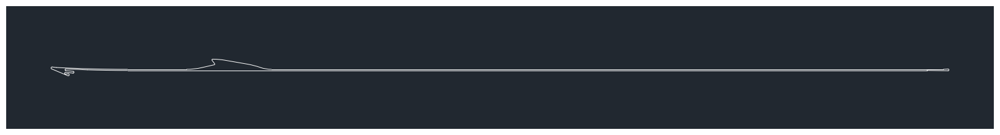

In [3]:
# The auditor.errors attribute stores severe errors, which may raise exceptions when rendering.
if not auditor.has_errors:
    fig = plt.figure()
    ax = fig.add_axes([0, 0, 1, 1])
    ctx = RenderContext(doc)
    out = MatplotlibBackend(ax)
    Frontend(ctx, out).draw_layout(doc.modelspace(), finalize=True)
    fig.savefig("your.png", dpi=300)

In [4]:
def circle_array(xc, yc, r, start, end):
    phi1 = start * np.pi / 180.0
    phi2 = end * np.pi / 180.0
    dphi = (phi2 - phi1) / np.ceil(200 * np.pi * r * (phi2 - phi1))  # 根据圆弧周长设置等间距
    array = np.arange(phi1, phi2, dphi)
    return xc + r * np.cos(array), yc + r * np.sin(array)


lines = []
circles = []
arcs = []
ellipses = []
splines = []
polylines = []

msp = doc.modelspace()
for entity in msp:
    transform = Matrix44()
    if entity.dxftype() == "LINE":
        start = transform.transform(entity.dxf.start)
        end = transform.transform(entity.dxf.end)
        lines.append((start, end))
    elif entity.dxftype() == "LWPOLYLINE":
        polyline = [transform.transform((p[0], p[1], 0)) for p in entity.get_points()]
        polylines.append(polyline)
    elif entity.dxftype() == "CIRCLE":
        center = transform.transform(entity.dxf.center)
        radius = entity.dxf.radius
        circles.append((center, radius))
    elif entity.dxftype() == "ARC":
        center = transform.transform(entity.dxf.center)
        radius = entity.dxf.radius
        start_angle = entity.dxf.start_angle
        end_angle = entity.dxf.end_angle
        arcs.append((center, radius, start_angle, end_angle))
    elif entity.dxftype() == "ELLIPSE":
        center = transform.transform(entity.dxf.center)
        major_axis_vec = Vec3(entity.dxf.major_axis)
        transformed_major_axis = transform.transform_direction(major_axis_vec)

        major_len = transformed_major_axis.magnitude
        angle_rad = math.atan2(transformed_major_axis.y, transformed_major_axis.x)
        rotation_deg = math.degrees(angle_rad)

        ratio = entity.dxf.ratio
        ellipses.append((center, major_len, ratio, rotation_deg))
    elif entity.dxftype() == "SPLINE":
        control_points = [transform.transform(p) for p in entity.control_points]
        fit_points = [transform.transform(p) for p in entity.fit_points]
        splines.append((control_points, fit_points))

print(f"lines:{len(lines)}")
print(f"circles:{len(circles)}")
print(f"arcs:{len(arcs)}")
print(f"ellipses:{len(ellipses)}")
print(f"splines:{len(splines)}")
print(f"polylines:{len(polylines)}")

lines:15
circles:0
arcs:8
ellipses:0
splines:0
polylines:1


In [5]:
def sample_arc(center_x, center_y, radius, start_angle_deg, end_angle_deg, num_points):
    """
    Samples evenly spaced points from a circular arc.

    Args:
        center_x (float): The x-coordinate of the center of the circle.
        center_y (float): The y-coordinate of the center of the circle.
        radius (float): The radius of the circle.
        start_angle_deg (float): The starting angle of the arc in degrees.
        end_angle_deg (float): The ending angle of the arc in degrees.
        num_points (int): The number of points to sample.

    Returns:
        numpy.ndarray: An array of shape (num_points, 2) containing the (x, y) coordinates.
    """
    # Convert angles from degrees to radians for NumPy's trigonometric functions
    start_angle_rad = np.deg2rad(start_angle_deg)
    end_angle_rad = np.deg2rad(end_angle_deg)

    # Generate an array of evenly spaced angles
    angles = np.linspace(start_angle_rad, end_angle_rad, num_points)

    # Calculate x and y coordinates using the parametric equation of a circle
    x_coords = center_x + radius * np.cos(angles)
    y_coords = center_y + radius * np.sin(angles)

    # Stack the coordinates into a single array
    return np.vstack((x_coords, y_coords)).T


all_lines = []

fig = go.Figure()

for idx, line in enumerate(lines):
    p1 = line[0]
    p2 = line[1]

    if idx in [1, 2, 4, 7, 8]:
        p1, p2 = p2, p1

    fig.add_shape(
        type="line",
        x0=p1[0],
        y0=p1[1],
        x1=p2[0],
        y1=p2[1],
        line=dict(color="black", width=2),
    )

    # startpoint
    # fig.add_annotation(
    #     x=p1[0],
    #     y=p1[1],
    #     text=f"line:{idx}",
    #     showarrow=True,
    #     arrowhead=2,  # Style of the arrowhead (optional)
    #     font=dict(size=12, color="red"),  # Customize font properties (optional)
    #     align="center",
    # )

    # midpoint
    # fig.add_annotation(
    #     x=(p1[0] + p2[0]) / 2.0,
    #     y=(p1[1] + p2[1]) / 2.0,
    #     text=f"line:{idx}",
    #     showarrow=True,
    #     arrowhead=2,  # Style of the arrowhead (optional)
    #     font=dict(size=12, color="red"),  # Customize font properties (optional)
    #     align="center",
    # )
    all_lines.append(((p1[0], p1[1]), (p2[0], p2[1])))

for idx, polyline in enumerate(polylines):
    for idx2 in range(len(polyline) - 1):
        p1 = polyline[idx2]
        p2 = polyline[idx2 + 1]
        fig.add_shape(
            type="line",
            x0=p1[0],
            y0=p1[1],
            x1=p2[0],
            y1=p2[1],
            line=dict(color="red", width=2),
        )

        # fig.add_annotation(
        #     x=l1[0],
        #     y=l1[1],
        #     text=f"pline:{idx}:{idx2}",
        #     showarrow=True,
        #     arrowhead=2,  # Style of the arrowhead (optional)
        #     font=dict(size=12, color="red"),  # Customize font properties (optional)
        #     align="center",
        # )

        # midpoint
        # fig.add_annotation(
        #     x=(p1[0] + p2[0]) / 2.0,
        #     y=(p1[1] + p2[1]) / 2.0,
        #     text=f"pline:{idx}:{idx2}",
        #     showarrow=True,
        #     arrowhead=2,  # Style of the arrowhead (optional)
        #     font=dict(size=12, color="red"),  # Customize font properties (optional)
        #     align="center",
        # )

        # invert points
        all_lines.append(((p2[0], p2[1]), (p1[0], p1[1])))

for idx, arc in enumerate(arcs):
    cx = arc[0][0]
    cy = arc[0][1]
    radius = arc[1]
    start_angle = arc[2]
    end_angle = arc[3]

    # fix angles of rollers
    if idx == 0:
        start_angle, end_angle = end_angle, start_angle
        start_angle -= 175
        end_angle -= 185
    elif idx == 3:
        start_angle, end_angle = end_angle, start_angle
        start_angle -= 210
        end_angle -= 150
    elif idx == 5:
        start_angle, end_angle = end_angle, start_angle
        start_angle -= 180
        end_angle -= 180

    arc_points = sample_arc(arc[0][0], arc[0][1], arc[1], start_angle, end_angle, 5)
    for idx2 in range(len(arc_points) - 1):
        p1 = arc_points[idx2]
        p2 = arc_points[idx2 + 1]

        fig.add_shape(
            type="line",
            x0=p1[0],
            y0=p1[1],
            x1=p2[0],
            y1=p2[1],
            line=dict(color="green", width=2),
        )

        # midpoint
        fig.add_annotation(
            x=(p1[0] + p2[0]) / 2.0,
            y=(p1[1] + p2[1]) / 2.0,
            text=f"arc:{idx}:{idx2}",
            showarrow=True,
            arrowhead=2,  # Style of the arrowhead (optional)
            font=dict(size=12, color="red"),  # Customize font properties (optional)
            align="center",
        )

        if idx in [4, 6, 7]:
            p1, p2 = p2, p1

        all_lines.append(((p1[0], p1[1]), (p2[0], p2[1])))

    fig.add_annotation(
        x=cx,
        y=cy,
        text=f"arc:{idx}",
        showarrow=False,
        arrowhead=2,  # Style of the arrowhead (optional)
        font=dict(size=12, color="blue"),  # Customize font properties (optional)
        align="center",
    )

start_x = [e[0][0] for e in all_lines]
start_y = [e[0][1] for e in all_lines]
fig.add_trace(go.Scatter(x=start_x, y=start_y, mode="markers", marker=dict(size=10, color="blue")))

# end_x = [e[1][0] for e in all_lines]
# end_y = [e[1][1] for e in all_lines]
# fig.add_trace(go.Scatter(x=end_x, y=end_y, mode="markers", marker=dict(size=5, color="red")))

fig.update_layout(xaxis=dict(range=[210000, 900000]), yaxis=dict(range=[945000, 959000]))
fig.show()

In [6]:
fig = go.Figure()
count = 0
for idx, line in enumerate(all_lines):
    fig.add_shape(
        type="line",
        x0=line[0][0],
        y0=line[0][1],
        x1=line[1][0],
        y1=line[1][1],
        line=dict(color="red", width=2),
    )

    fig.add_annotation(
        x=line[0][0],
        y=line[0][1],
        text=f"str:{idx}",
        showarrow=True,
        arrowhead=2,  # Style of the arrowhead (optional)
        font=dict(size=12, color="blue"),  # Customize font properties (optional)
        align="left",
    )

    fig.add_annotation(
        x=line[1][0],
        y=line[1][1] + 100,
        text=f"end:{idx}",
        showarrow=False,
        font=dict(size=12, color="black"),  # Customize font properties (optional)
        align="right",
    )

fig.update_layout(xaxis=dict(range=[210000, 900000]), yaxis=dict(range=[945000, 959000]))
fig.show()

In [7]:
def get_index_of_min_distance_point(reference_point, points):
    """
    Finds the index of the point in a list that has the minimum distance
    to a given reference point.

    Args:
        points (list): A list of points, where each point is a tuple/list of coordinates.
        reference_point (tuple/list): The reference point.

    Returns:
        int: The index of the point with the minimum distance, or -1 if the list is empty.
    """
    if not points:
        return -1

    min_distance = float("inf")
    min_index = -1

    for i, point in enumerate(points):
        distance = math.dist(point, reference_point)
        if distance < min_distance:
            min_distance = distance
            min_index = i

    return min_index, min_distance


# sort all lines from a starting point
all_lines_copy = list(all_lines)
sorted_lines = [all_lines_copy.pop(15)]

count = 1
while len(all_lines_copy):
    end_element = sorted_lines[-1]
    p_start, p_end = end_element

    start_positions = [e[0] for e in all_lines_copy]
    end_positions = [e[1] for e in all_lines_copy]

    min_dist_idx_start, min_distance_start = get_index_of_min_distance_point(p_end, start_positions)
    min_dist_idx_end, min_distance_end = get_index_of_min_distance_point(p_end, end_positions)

    # print(f"idx:{count} min_distances:", min_distance_start, min_distance_end)
    count += 1

    min_dist_idx = min_dist_idx_start
    if min_distance_end < min_distance_start:
        min_dist_idx = min_dist_idx_end

    sorted_lines.append(all_lines_copy.pop(min_dist_idx))

# manual rotation
k = -3
deque_obj = deque(sorted_lines)
deque_obj.rotate(k)
sorted_lines = list(deque_obj)

fig = go.Figure()
count = 0
for idx, line in enumerate(sorted_lines):
    fig.add_shape(
        type="line",
        x0=line[0][0],
        y0=line[0][1],
        x1=line[1][0],
        y1=line[1][1],
        line=dict(color="red", width=2),
    )

    fig.add_annotation(
        x=line[0][0],
        y=line[0][1],
        text=f"{idx}",
        showarrow=True,
        arrowhead=2,  # Style of the arrowhead (optional)
        font=dict(size=12, color="blue"),  # Customize font properties (optional)
        align="center",
    )

    fig.add_annotation(
        x=line[1][0] + 500,
        y=line[1][1] + 300,
        text=f"{idx}",
        showarrow=False,
        font=dict(size=12, color="black"),  # Customize font properties (optional)
        align="center",
    )

start_x = [e[0][0] for e in sorted_lines]
start_y = [e[0][1] for e in sorted_lines]
fig.add_trace(go.Scatter(x=start_x, y=start_y, mode="markers", marker=dict(size=10, color=0)))

end_x = [e[1][0] for e in sorted_lines]
end_y = [e[1][1] for e in sorted_lines]
fig.add_trace(go.Scatter(x=end_x, y=end_y, mode="markers", marker=dict(size=7, color=1)))

fig.update_layout(xaxis=dict(range=[210000, 900000]), yaxis=dict(range=[945000, 959000]))
fig.show()

In [8]:
def interpolate_line_min_dist(p1, p2, min_dist=2):
    p0 = np.array(p1)
    p1 = np.array(p2)

    v = p1 - p0
    length = np.linalg.norm(v)
    u = v / length

    points = []
    current_distance = 0
    while current_distance <= length:
        point = p0 + current_distance * u
        points.append(point)
        current_distance += min_dist

    # Calculate number of points based on fixed distance
    num_points = int(length / min_dist) + 1
    x_coords = np.linspace(p0[0], p1[0], num=num_points)
    y_coords = np.linspace(p0[1], p1[1], num=num_points)
    points = np.column_stack((x_coords, y_coords))

    return points


p1 = np.array([5, 5])
p2 = np.array([0, 0])
interpolate_line_min_dist(p1, p2)

array([[5.        , 5.        ],
       [3.33333333, 3.33333333],
       [1.66666667, 1.66666667],
       [0.        , 0.        ]])

In [9]:
list(sorted_lines)[0]

((274202.91485060967, 950790.2069428755),
 (261115.88929788244, 951047.203116261))

Total points: 1346925


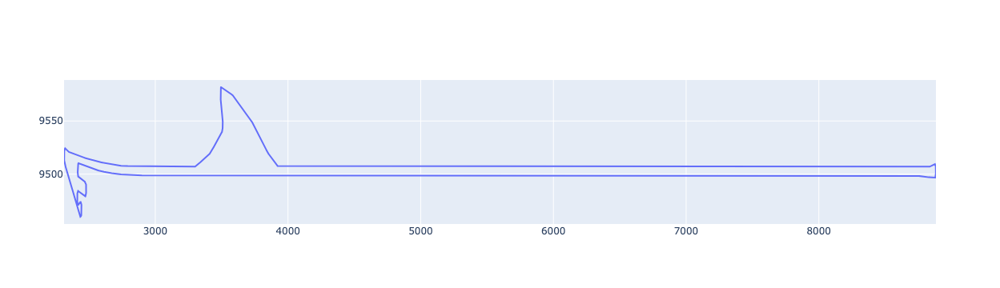

In [10]:
sorted_interpolated_points = []
circular_sorted_lines = sorted_lines
circular_sorted_lines.append(circular_sorted_lines[0])

for idx in range(len(circular_sorted_lines) - 1):
    l1 = circular_sorted_lines[idx]
    l2 = circular_sorted_lines[idx + 1]
    p1, _ = l1
    p2, _ = l2

    line_points = list(interpolate_line_min_dist(p1, p2, min_dist=1))
    sorted_interpolated_points += line_points

    # print(f"idx:{idx} {len(line_points)}")

print(f"Total points: {len(sorted_interpolated_points)}")

px = np.array([e[0] for e in sorted_interpolated_points]) / 100.0
py = np.array([e[1] for e in sorted_interpolated_points]) / 100.0

fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=px,
        y=py,
        # mode="markers",
        marker=dict(size=3, color=0),
        connectgaps=True,
        name="Belt points",
    )
)
# fig.update_layout(xaxis=dict(range=[210000, 900000]), yaxis=dict(range=[945000, 959000]))
fig.show()

# plt.scatter(px, py, s=2, alpha=0.5)
# plt.plot(px, py)
# plt.show()

In [14]:
import json

sorted_interpolated_points_for_json = [[e[0], e[1]] for e in sorted_interpolated_points]

with open('plot_interpolated_points.json', 'w', encoding='utf-8') as f:
    json.dump(sorted_interpolated_points_for_json, f, ensure_ascii=False, indent=4)